# 8.5 — Imbalanced Classes

**Chapter 8, section 8.3.2**, and the starting point for **Exercise 7**.

**The question this notebook answers:** on a dataset where one class is a hundred times rarer than
the other, can accuracy tell a useful classifier from a useless one?

It cannot, and the notebook trains two models to show it. They differ in exactly one place — the
aggregation step, where the weighted version accumulates the two classes separately and combines
them as $w_0g_0 + w_1g_1$. Everything else is shared: the same data, the same mini-batches, the
same update rule, the same number of iterations. Their accuracies differ in the third decimal
place. Their confusion matrices do not.

Source: `Notebooks old/Spark-Example-20b-Imbalanced-Classes.ipynb`, rebuilt.

> **What the rebuild changed, and why.** The source notebook carried the whole comparison twice,
> as two ninety-line functions differing in four lines, each dispatching over six optimizer update
> rules — SGD, Momentum, Nesterov, Adam, AdaGrad and RMSProp — of which the chapter teaches none
> and uses one. Here the loop is written once and the aggregation step is the argument, so the
> four lines that carry the idea are the only thing that differs between the two runs. The source
> also called the weighted version without its `train_size` argument, which silently set the
> sampling fraction to 50000 and made that model train on the entire dataset while the unweighted
> one genuinely mini-batched. Both sides now sample identically, so the comparison isolates the
> class weighting.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))
os.makedirs(SCRATCH, exist_ok=True)

spark = (SparkSession.builder
         .appName("CS777-8.5")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version)

Spark 4.2.0


---

## 1. A 99:1 dataset

The same two-blob construction as 8.4, with one number changed: `ratio_positive` drops from
$0.5$ to $0.01$. Ninety-nine thousand negatives, one thousand positives.

In [2]:
from sklearn.datasets import make_blobs
import pandas as pd
import matplotlib.cm as cm

n = 100000                                   # total number of samples
ratio_positive = 0.01                        # a very imbalanced dataset
n_samples = [int(n * (1 - ratio_positive)), int(n * ratio_positive)]
print("class sizes:", n_samples)

X, y = make_blobs(n_samples=n_samples, centers=None, n_features=2,
                  cluster_std=1.5, random_state=2)

class sizes: [99000, 1000]


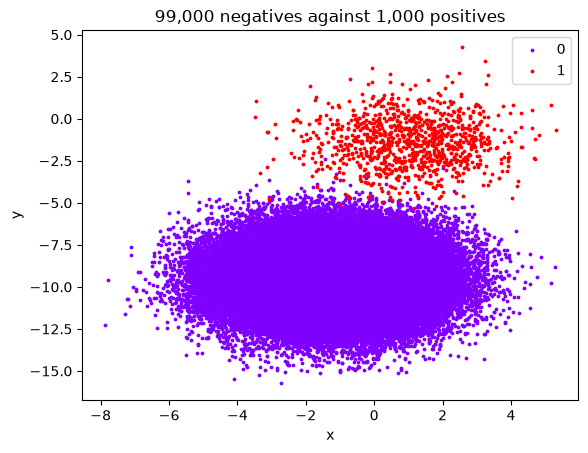

In [3]:
df = pd.DataFrame(dict(x=X[:, 0], y=X[:, 1], label=y))
colors = dict(zip(sorted(set(y)), cm.rainbow(np.linspace(0, 1, len(set(y))))))
fig, ax = plt.subplots()
for key, group in df.groupby('label'):
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key,
               color=colors[key].reshape(1, -1), s=3)
plt.title('99,000 negatives against 1,000 positives')
plt.show()

---

## 2. The class weights

The weight for class $j$ is

$$w_j = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_{\text{samples}_j}}$$

which is larger for rarer classes. The construction has one property that makes it the natural
choice: the **total** weight contributed by a class,

$$n_{\text{samples}_j}\,w_j = \frac{n_{\text{samples}}}{n_{\text{classes}}},$$

does not depend on $j$ at all. Every class ends up contributing the same total to the objective,
whatever its size.

In [4]:
w0 = n / (2 * n_samples[0])
w1 = n / (2 * n_samples[1])
print(f"w0 = {w0:.4f}   w1 = {w1:.4f}   ratio = {w1 / w0:.1f} : 1")

# the property above, checked rather than asserted
assert np.isclose(n_samples[0] * w0, n_samples[1] * w1)
print(f"each class contributes {n_samples[0] * w0:.0f} of total weight")

w0 = 0.5051   w1 = 50.0000   ratio = 99.0 : 1
each class contributes 50000 of total weight


---

## 3. The data as RDDs

Note the last cell of this section: the class counts the weights are computed from are themselves
a property of a distributed dataset, so in a real setting obtaining them costs one extra pass over
the data before training begins. It is one pass, done once, and it is exactly what Spark's
distributed aggregation is for.

In [5]:
rdd_X = sc.parallelize(X)
rdd_y = sc.parallelize(y)

traindata, testdata = rdd_y.zip(rdd_X).randomSplit([0.8, 0.2], seed=12345)
traindata = traindata.map(lambda x: (x[0], np.append(x[1], 1)))   # fold in the intercept
traindata.cache()
train_size = traindata.count()

testdata1 = testdata.map(lambda x: (x[0], np.append(x[1], 1)))
testdata1.cache()
test_num = testdata1.count()

print("training examples:", train_size)
print("test examples:", test_num)

training examples: 79966
test examples: 20034


In [6]:
# The counts the weights need, obtained the way they would be on a real dataset: one pass.
counts = traindata.map(lambda r: int(r[0])).countByValue()
print("training class counts:", dict(counts))
print("weights from the training split:",
      {c: round(train_size / (2 * k), 4) for c, k in sorted(counts.items())})

training class counts: {0: 79163, 1: 803}
weights from the training split: {0: 0.5051, 1: 49.792}


---

## 4. The aggregation step, twice

This is the whole difference between the two models.

**Unweighted.** One `treeAggregate` over the sampled mini-batch, accumulating a triple: the summed
gradient, the summed loss, and the count. Every example contributes on equal terms.

In [7]:
def aggregate_unweighted(min_batch, bc_weights, parameter_size):
    res = min_batch.treeAggregate((np.zeros(parameter_size), 0, 0),
          lambda x, y: (x[0]
                      + (y[1]) * (-y[0] + (1 / (np.exp(-np.dot(y[1], bc_weights)) + 1))),
                        x[1]
                      + y[0] * (-(np.dot(y[1], bc_weights)))
                      + np.log(1 + np.exp(np.dot(y[1], bc_weights))),
                        x[2] + 1),
          lambda x, y: (x[0] + y[0], x[1] + y[1], x[2] + y[2]))

    gradients   = res[0]
    sum_cost    = res[1]
    num_samples = res[2]
    return gradients, sum_cost, num_samples

**Weighted.** The mini-batch is filtered into its two classes, each is aggregated separately with
the *identical* `seqOp`, and the two partial gradients are combined as $w_0g_0 + w_1g_1$.

In [8]:
def aggregate_weighted(min_batch, bc_weights, parameter_size):
    # Positive class: only the samples labeled 1 are filtered and then processed.
    res1 = min_batch.filter(lambda x: x[0] == 1).treeAggregate(
          (np.zeros(parameter_size), 0, 0),
          lambda x, y: (x[0] + (y[1]) * (-y[0] + (1 / (np.exp(-np.dot(y[1], bc_weights)) + 1))),
                        x[1] + y[0] * (-(np.dot(y[1], bc_weights))) + np.log(1 + np.exp(np.dot(y[1], bc_weights))),
                        x[2] + 1),
          lambda x, y: (x[0] + y[0], x[1] + y[1], x[2] + y[2]))

    # Negative class: identical, but filtering on label 0.
    res0 = min_batch.filter(lambda x: x[0] == 0).treeAggregate(
          (np.zeros(parameter_size), 0, 0),
          lambda x, y: (x[0] + (y[1]) * (-y[0] + (1 / (np.exp(-np.dot(y[1], bc_weights)) + 1))),
                        x[1] + y[0] * (-(np.dot(y[1], bc_weights))) + np.log(1 + np.exp(np.dot(y[1], bc_weights))),
                        x[2] + 1),
          lambda x, y: (x[0] + y[0], x[1] + y[1], x[2] + y[2]))

    # The total gradients are a weighted sum.
    gradients   = w0 * res0[0] + w1 * res1[0]
    sum_cost    = w0 * res0[1] + w1 * res1[1]
    num_samples = res0[2] + res1[2]
    return gradients, sum_cost, num_samples

Two observations about the weighted version.

**It stays correct under any partitioning.** $w_0g_0 + w_1g_1$ is a weighted sum of vectors, so it
is still associative and still has the zero vector as its identity. Nothing about class weighting
disturbs the property that lets partial gradients be combined in any order.

**It costs an extra job per iteration.** `filter` is a narrow transformation and free, but the two
`treeAggregate` calls are two separate Spark **actions**, so the weighted run launches two
aggregation jobs per iteration where the unweighted one launches one. A single-pass version is
perfectly possible — keep two accumulators inside one aggregate and apply the weights on the
driver afterwards — and is not used here because the two-call form makes the idea visible.

---

## 5. One training loop, with the aggregation as its argument

The loop below is shared by both models. It samples a mini-batch, calls whichever aggregation it
was given, adds the regularization terms on the driver, and takes an **RMSProp** step: a gradient
step whose length is divided by a running root-mean-square of recent gradient magnitudes, so that
each coefficient gets its own effective step size. RMSProp is not developed in this chapter; it is
the update rule the source notebook used, kept so that the two models are compared on equal terms.

Note where the division by the count happens. The aggregation returns a **sum** and a **count**,
never an average, and the division onto the driver happens after the reduction has finished. That
is the sum-and-count pattern, and it is what keeps the result independent of how the data happened
to be partitioned.

In [9]:
def train(aggregate, max_iteration=20, learningRate=0.01, regularization=0.0,
          mini_batch_size=50000, tolerance=1e-7, decay=0.9, label=""):
    parameter_size = len(traindata.first()[1])
    np.random.seed(0)
    parameter_vector = np.random.normal(0, 0.1, parameter_size)
    gti = np.zeros(parameter_size)
    epsilon = 1e-7
    prev_cost, L_cost = 0, []

    for i in range(max_iteration):
        bc_weights = parameter_vector
        min_batch = traindata.sample(False, mini_batch_size / train_size, 1 + i)

        gradients, sum_cost, num_samples = aggregate(min_batch, bc_weights, parameter_size)

        cost = sum_cost / num_samples + regularization * (np.square(parameter_vector).sum())
        gradient_derivative = (1.0 / num_samples) * gradients + 2 * regularization * parameter_vector

        # RMSProp: scale the step by a running root-mean-square of the gradient.
        sq_grad = gradient_derivative ** 2
        exp_grad = decay * gti / (i + 1) + (1 - decay) * sq_grad
        parameter_vector = parameter_vector - learningRate / np.sqrt(exp_grad + epsilon) * gradient_derivative
        gti += sq_grad

        print(f"{label} iteration {i:2}  cost = {cost:.6f}  batch = {num_samples}")
        if abs(cost - prev_cost) < tolerance:
            print("  stopping: the cost has stopped moving")
            break
        prev_cost = cost
        L_cost.append(cost)

    return parameter_vector, L_cost

Both models are now trained at **identical settings** — twenty iterations, a learning rate of
$0.01$, no regularization, and the same mini-batch size, which means the same sampling fraction
and the same seed sequence on both sides.

In [10]:
params_unweighted, cost_unweighted = train(aggregate_unweighted, label="unweighted")

unweighted iteration  0  cost = 0.481346  batch = 50060


unweighted iteration  1  cost = 0.361409  batch = 50058
unweighted iteration  2  cost = 0.326440  batch = 50064
unweighted iteration  3  cost = 0.298178  batch = 49977


unweighted iteration  4  cost = 0.273736  batch = 49965


unweighted iteration  5  cost = 0.252544  batch = 49966
unweighted iteration  6  cost = 0.233599  batch = 49953
unweighted iteration  7  cost = 0.217536  batch = 50148


unweighted iteration  8  cost = 0.201942  batch = 50180


unweighted iteration  9  cost = 0.188600  batch = 50161
unweighted iteration 10  cost = 0.177065  batch = 50177
unweighted iteration 11  cost = 0.166044  batch = 49911


unweighted iteration 12  cost = 0.155783  batch = 49968
unweighted iteration 13  cost = 0.146919  batch = 49921


unweighted iteration 14  cost = 0.139430  batch = 49971
unweighted iteration 15  cost = 0.131874  batch = 50085
unweighted iteration 16  cost = 0.125542  batch = 50114


unweighted iteration 17  cost = 0.119444  batch = 50083
unweighted iteration 18  cost = 0.113511  batch = 50125


unweighted iteration 19  cost = 0.107709  batch = 49904


In [11]:
params_weighted, cost_weighted = train(aggregate_weighted, label="weighted  ")

weighted   iteration  0  cost = 0.542242  batch = 50060


weighted   iteration  1  cost = 0.488856  batch = 50058


weighted   iteration  2  cost = 0.474634  batch = 50064
weighted   iteration  3  cost = 0.458484  batch = 49977


weighted   iteration  4  cost = 0.446331  batch = 49965


weighted   iteration  5  cost = 0.446200  batch = 49966
weighted   iteration  6  cost = 0.427932  batch = 49953


...

weighted   iteration 13  cost = 0.365550  batch = 49921


weighted   iteration 14  cost = 0.367408  batch = 49971
weighted   iteration 15  cost = 0.350119  batch = 50085


weighted   iteration 16  cost = 0.366862  batch = 50114


weighted   iteration 17  cost = 0.359541  batch = 50083
weighted   iteration 18  cost = 0.341377  batch = 50125


weighted   iteration 19  cost = 0.331040  batch = 49904


The weighted run's printed costs are far larger, and that is arithmetic rather than a worse fit:
the weighted sum multiplies the positive class's loss by $50$ and the negative class's by $0.51$,
so the accumulated objective is on a different scale. The two cost columns are not comparable with
each other. Only the test-set behaviour is.

---

## 6. The confusion matrices

The evaluation is 8.4's, applied to both models over the same held-out test set.

In [12]:
def contingency(params, name):
    preds = testdata1.map(lambda x: (x[0], 1 if np.dot(x[1], params) > 0 else 0)).cache()
    tp = preds.map(lambda x: 1 if (x[0] == 1) and (x[1] == 1) else 0).reduce(lambda a, b: a + b)
    fp = preds.map(lambda x: 1 if (x[0] == 0) and (x[1] == 1) else 0).reduce(lambda a, b: a + b)
    tn = preds.map(lambda x: 1 if (x[0] == 0) and (x[1] == 0) else 0).reduce(lambda a, b: a + b)
    fn = preds.map(lambda x: 1 if (x[0] == 1) and (x[1] == 0) else 0).reduce(lambda a, b: a + b)
    preds.unpersist()
    acc = (tp + tn) / (tp + tn + fp + fn)
    f1 = tp / (tp + 0.5 * (fp + fn))
    rec = tp / (tp + fn)
    prec = tp / (tp + fp) if (tp + fp) else float('nan')
    print(f"--Contingency matrix: {name}--")
    print(f" TP:{tp:6}  FP:{fp:6}")
    print(f" FN:{fn:6}  TN:{tn:6}")
    print("----------------------")
    print(f"Accuracy = {acc}  \nF1 = {f1}")
    return dict(model=name, TP=tp, FP=fp, FN=fn, TN=tn,
                accuracy=acc, precision=prec, recall=rec, F1=f1)


row_unweighted = contingency(params_unweighted, "unweighted")

--Contingency matrix: unweighted--
 TP:   102  FP:     0
 FN:    95  TN: 19837
----------------------
Accuracy = 0.9952580612957972  
F1 = 0.6822742474916388


In [13]:
row_weighted = contingency(params_weighted, "weighted")

--Contingency matrix: weighted--
 TP:   142  FP:    16
 FN:    55  TN: 19821
----------------------
Accuracy = 0.9964560247579115  
F1 = 0.8


In [14]:
summary = pd.DataFrame([row_unweighted, row_weighted]).set_index("model")
print(f"test set: {test_num} observations, of which "
      f"{row_unweighted['TP'] + row_unweighted['FN']} positive\n")
print(summary[["TP", "FP", "FN", "TN"]].to_string())
print()
print(summary[["accuracy", "precision", "recall", "F1"]].round(4).to_string())

test set: 20034 observations, of which 197 positive

             TP  FP  FN     TN
model                         
unweighted  102   0  95  19837
weighted    142  16  55  19821

            accuracy  precision  recall      F1
model                                          
unweighted    0.9953     1.0000  0.5178  0.6823
weighted      0.9965     0.8987  0.7208  0.8000


---

## Conclusion

Read the accuracy column first, and then stop trusting it. The two models are separated by a
fraction of a percentage point, and on that evidence alone either would be reported as excellent
and the choice between them would be arbitrary. Read the four counts instead and the two models
are not close: the weighted one finds substantially more of the positives, and it does so at the
cost of a handful of false positives that the unweighted model, which barely predicts the positive
class at all, never had the opportunity to make.

That last point is worth stating plainly, because a precision of $1.0$ looks like the best possible
result. **A classifier that almost never predicts the positive class cannot make a false positive**,
so its perfect precision is a description of its timidity rather than of its skill. This is the
concrete reason the chapter's third response to imbalance — choose metrics that survive it — is not
optional alongside the first two.

The mechanism behind the improvement is entirely in the four lines of section 4. Every example
contributes $x_i(\sigma(\theta_i) - y_i)$ to the gradient, so with ninety-nine times more negatives
the direction of the optimization is set almost entirely by the majority class. Weighting each
class inversely to its frequency makes the two contribute equal totals, and the optimization starts
paying attention to the rare class. Nothing about the distributed computation had to change to
allow it: a weighted sum of vectors is still a sum of vectors.

In production, `LogisticRegression(weightCol=...)` does exactly this, in one aggregation rather
than two, by carrying the weight as a column alongside the features.